# Exploring cell populations with dimensionality reduction methods

This is a hands-on notebook for comparing dimensionality reduction methods using data of B-cells and plasma cells from the **Human Immune Health Atlas**. The original dataset contains 160,632 cells in a downloadable ~1.12 GB H5AD file. To simplify the exercise, we will use a small subset of the original data.

## Learning objectives

- **Biological:** explore how annotated B-cell and plasma cell types look like in gene-expression space.
- **Technical:** implement PCA, t-SNE, and UMAP independently. Interprete the output given by each method to the same input data. Discuss advantages and disadvantages of each method and why would you chose one method over the other for specific goals.   

## Data subset and provenance

The source data are Human Immune Health Atlas **B and Plasma cells**, from the [Human Immune Health Atlas collection](https://cellxgene.cziscience.com/collections/77f9d7e9-5675-49c3-abed-ce02f39eef1b). It contains five annotated cell types. For a manageable learning example, we will use a subset of 1,000 cells from each type in a file stored in the GitHub repository. 

The code to obtain this subset follows below (**you do not have to run it, the code is here only for documentation**).

```
from pathlib import Path
import shutil
import urllib.request

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from importlib.metadata import version

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, facecolor="white")
RANDOM_SEED = 17
CELLS_PER_TYPE = 1_000
DATASET_URL = "https://datasets.cellxgene.cziscience.com/b6986a7f-981e-4e04-93ed-57f444749b8b.h5ad"
DATA_DIR = Path("data") / "human_immune_health_atlas_b_plasma"
DATA_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_H5AD = DATA_DIR / "source.h5ad"
SUBSET_H5AD = DATA_DIR / f"subset_{CELLS_PER_TYPE}_per_type_seed_{RANDOM_SEED}.h5ad"

print(f"Scanpy {version('scanpy')}; AnnData {version('anndata')}")

def download_if_needed(url: str, destination: Path) -> None:
    """Download a public dataset to the cache, preserving download errors."""
    if destination.exists() and destination.stat().st_size > 0:
        return
    temporary = destination.with_name(destination.name + ".part")
    request = urllib.request.Request(url, headers={"User-Agent": "single-cell-course-notebook/1.0"})
    try:
        with urllib.request.urlopen(request, timeout=120) as response, temporary.open("wb") as output:
            expected_size = response.headers.get("Content-Length")
            if expected_size:
                print(f"Downloading {int(expected_size) / (1024 ** 3):.2f} GiB source dataset...")
            shutil.copyfileobj(response, output)
        if temporary.stat().st_size == 0:
            raise IOError(f"The server returned an empty file for {url}")
        temporary.replace(destination)
    except Exception:
        temporary.unlink(missing_ok=True)
        raise
```

# 1. Load the RNA expression data

The Human Immune Health Atlas provides the gene expression matrix and annotations in the H5AD file in AnnData format. We will first load the file and inspect it.

Here you can find information about the Python package for [AnnData](https://anndata.readthedocs.io/en/latest/) (annotated data matrices). AnnData is a data structure used for single-cell sequencing data analysis and handles annotated matrices. The core matrix contains genes and gene counts, while two other matrices contain (1) cell level and (2) gene level information.  

You will notice there is a **lot of data available** in this object. For the purposes of this practical exercise, **we will focus only on gene expression and cell annotation**. You will first inspect the data, then prepare it with the code we provide you and lastly code yourself to obtain plots for different dimensionality reduction methods.  

Note: be patient when running the coding cells, some may take some processing time (nothing more than a minute). 

In [1]:
import anndata as ad
import scanpy as sc

# Load the .h5ad dataset stored in this Git repository
adata = ad.read_h5ad("data/subset_1000_per_type_seed_17.h5ad")

# Basic print inspection
print(adata)

# Check first few rows of cell or gene metadata
print(adata.obs.head())
print(adata.var.head())

# Calculate and inspect quality control metrics we will use later to prepare the data for dimensionality reduction
sc.pp.calculate_qc_metrics(adata, inplace=True)
print(adata.obs[["n_genes_by_counts", "total_counts"]])

# Check data types and the number of cells per type
display(adata.obs["cell_type"].value_counts().sort_index().rename("cells"))

AnnData object with n_obs × n_vars = 5000 × 32357
    obs: 'cohort.cohortGuid', 'sample.sampleKitGuid', 'specimen.specimenGuid', 'pipeline.fileGuid', 'subject.birthYear', 'subject.ageAtFirstDraw', 'subject.ageGroup', 'subject.race', 'subject.ethnicity', 'subject.cmv', 'subject.bmi', 'sample.visitName', 'sample.drawYear', 'sample.subjectAgeAtDraw', 'batch_id', 'pool_id', 'chip_id', 'well_id', 'original_barcodes', 'cell_name', 'n_reads', 'n_umis', 'n_genes', 'total_counts_mito', 'pct_counts_mito', 'doublet_score', 'AIFI_L1', 'AIFI_L2', 'AIFI_L3', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'tissue_type', 'suspension_type', 'assay_ontology_term_id', 'sex_ontology_term_id', 'donor_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'cell_type_ontology_term_id', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'mito', 'n_cells_by_counts', 'mean_coun

cell_type
plasma cell                  1000
memory B cell                1000
naive B cell                 1000
transitional stage B cell    1000
Be cell                      1000
Name: cells, dtype: int64

In [2]:
# To inspect the matrix dimensions:
print(f"Cells: {adata.n_obs}")
print(f"Genes: {adata.n_vars}")

Cells: 5000
Genes: 32357


# 2. Inspect and prepare the data

We will visualize the data and apply some filtering to remove noise and non-representative data. Our **quality control (QC) plots are grouped by annotated cell type**.    

Based on this [tutorial from EvoByte](https://evo-byte.com/scanpy-scrna-seq-qc-tutorial/), we will inspect the distributions below to understand our filtering choices. In this exercise, we will remove:

- cells with fewer than 200 detected genes (to remove cells that didn't capture enough RNA to be informative)
- cells with more than 2500 detected genes (to remove cells that were possibly merged in the sequencing process)
- cells with more than 5% mitochondrial counts (to remove cells under stress or lysis, or that have ruptured and leaked cytoplasmic RNA, retaining mostly mitochondrial RNA)
- genes detected in fewer than three retained cells (creating noise and sparse matrices)

Note that this data uses Ensembl IDs in `adata.var_names` and stores gene symbols in `adata.var["gene_symbols"]`. Ensembl IDs are unique, stable, machine-friendly identifiers assigned by the Ensembl Genome Browser project. [Ensembl](https://ensemblgenomes.org/) offer important and widely used biological databases for the scientific community. It is a joint scientific project coordinated by the European Bioinformatics Institute (EMBL-EBI) and the Wellcome Sanger Institute that provides a centralized genome browser and database for vertebrate and model organism genomes.   

The meaning of some variables we will use:  

- **n_genes_by_counts**: number of unique genes detected in a cell.
- **total_counts**: total RNA counts per cell.
- **pct_counts_mt**: the percentage of the counts that are attributed to mitochondrial genes.

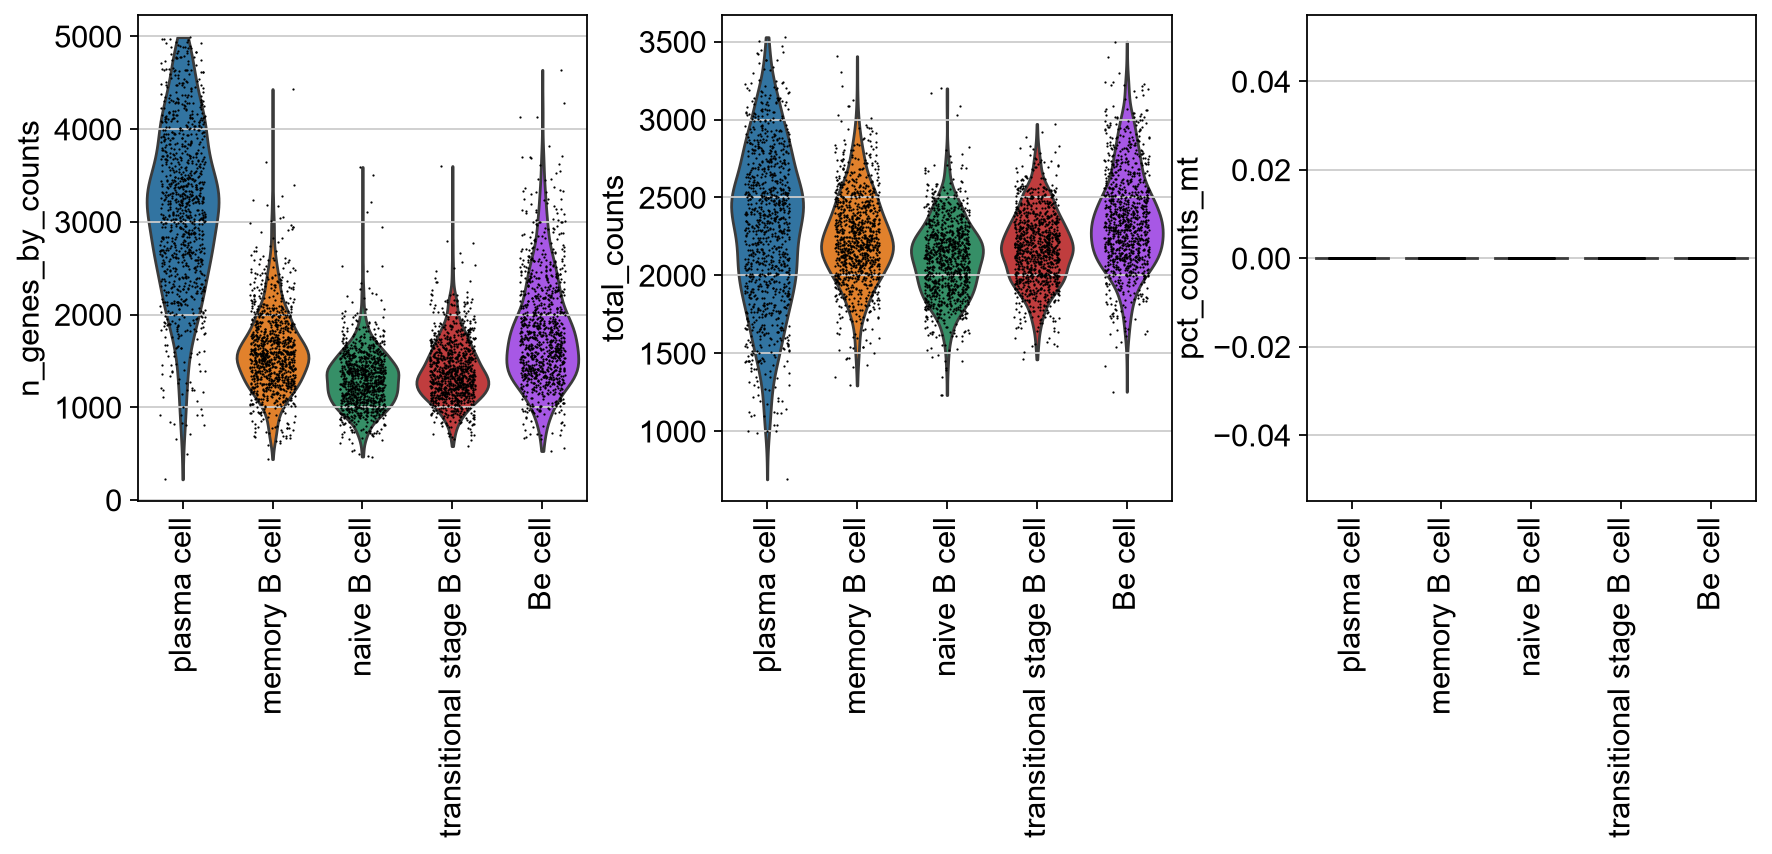

                           n_genes_by_counts  total_counts  pct_counts_mt
cell_type                                                                
plasma cell                           3187.5   2332.291504            0.0
memory B cell                         1572.0   2217.753906            0.0
naive B cell                          1283.5   2111.875977            0.0
transitional stage B cell             1347.0   2173.404785            0.0
Be cell                               1728.0   2324.939941            0.0


In [3]:
# Create a boolean flag (True/False) for every gene: does it start with "MT-"?
# We use .upper() to ensure we catch "mt-", "MT-", etc.
adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")

# Compute quality metrics. 
# It uses the "mt" flag from above to calculate what percentage of counts in each cell come from mitochondrial genes.
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

# Increase font sizes of the plot below
sc.set_figure_params(fontsize=14)

# Create violin plots to visualize distributions
# groupby="cell_type" splits the plot so we can compare distributions across different cell types.
# multi_panel=True separates the 3 metrics into their own distinct plots.
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"], #These indicate our 3 QC columns (the ones we are applying the filtering to)
    groupby="cell_type",
    multi_panel=True,
    jitter=0.25,
    rotation=90
)

# Print a summary table.
# Groups cells by type, picks our 3 QC columns, and calculates the median value.
# 'observed=True' is used to avoid Python/Pandas warnings regarding categorical data types.
print(adata.obs.groupby("cell_type", observed=True)[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].median())

In [4]:
# Inspect numeric summaries of the QC variables.
adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe()

,n_genes_by_counts,total_counts,pct_counts_mt
count,5000.000000,5000.000000,5000.0
mean,1857.552200,2236.406006,0.0
std,871.925653,346.011353,0.0
min,223.000000,690.937195,0.0
25%,1267.000000,2016.300629,0.0
50%,1574.000000,2213.565430,0.0
75%,2166.750000,2436.362122,0.0
max,4991.000000,3528.958740,0.0


## 2.1 Filtering

Apply filtering and inspect the data after filtering.

Original number of cells: 5,000 5,000 cells and 32,357 genes.
Retained 4,933 of 5,000 cells and 17,048 genes.


cell_type
plasma cell                   934
memory B cell                1000
naive B cell                 1000
transitional stage B cell    1000
Be cell                       999
Name: cells, dtype: int64

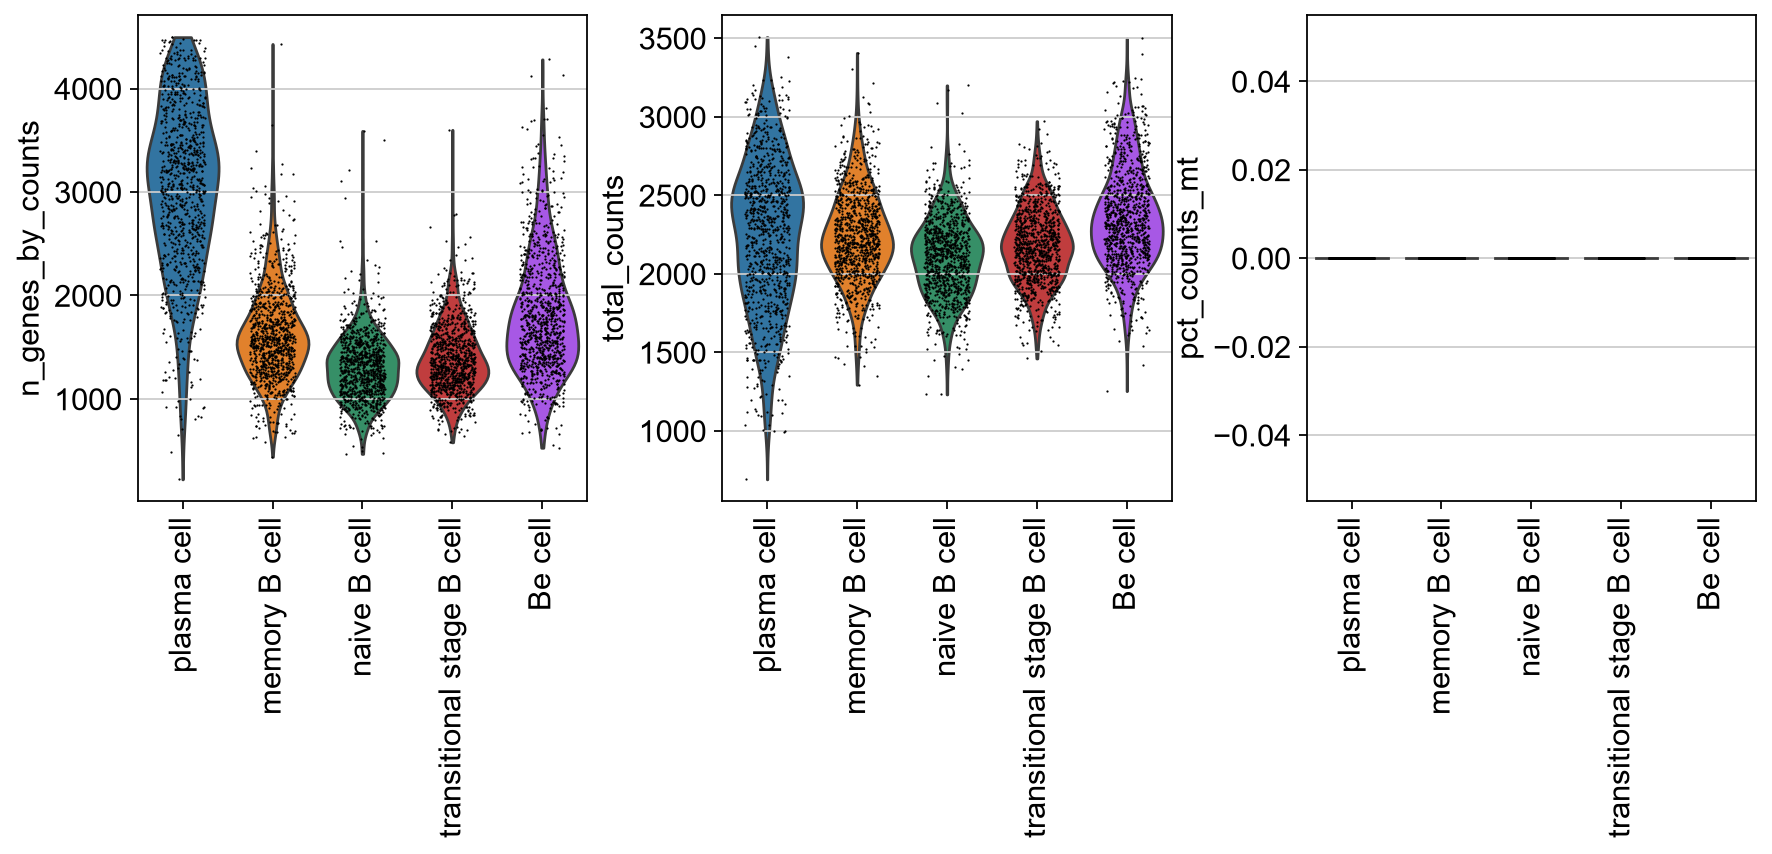

In [60]:
# Record the original cell count so we can calculate how much data we kept later.
cells_before = adata.n_obs
print(f"Original number of cells: {adata.n_obs:,} {cells_before:,} cells and {adata.n_vars:,} genes.")

# Remove "empty" droplets or dead cells that don't meet a minimum threshold of genes. Remove cells with too many genes
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_cells(adata, max_genes=4500)

# Remove "stressed" or ruptured cells where mitochondrial content is too high (> 5%).
# We use .copy() here. This creates a new object in memory, preventing errors when you try to modify the data later.
adata = adata[adata.obs["pct_counts_mt"] <= 5].copy()

# Remove "noise." Genes detected in fewer than 3 cells are usually not informative for downstream analysis, so we drop them to keep the matrix clean and smaller.
sc.pp.filter_genes(adata, min_cells=3)

# Report the results. The ":," formatting makes large numbers easier to read (e.g., 1,000 vs 1000).
print(f"Retained {adata.n_obs:,} of {cells_before:,} cells and {adata.n_vars:,} genes.")

# Show the class composition. This confirms we haven't accidentally wiped out a specific, rare cell type during our filtering process.
display(adata.obs["cell_type"].value_counts().sort_index().rename("cells"))

# Final visualization to verify that the filtering was effective and the distribution of the remaining cells looks as expected.
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    groupby="cell_type",
    multi_panel=True,
    jitter=0.25,
    rotation=90
)

## 2.2 Normalization and feature selection

In this step, we will: preserve raw counts in a layer, normalize each cell to a common library size (10,000 counts), log-transform and do feature selection. In broad terms, **normalization means adjusting values so they can be fairly compared**. During sequencing, for technical reasons, some cells get more depth coverage than others. This, for instance, reflects methodological differences that do not reflect the true biological signals. To remove this technical bias, we normalize the data. Another relevant aspect is that we may compare naturally larger cells with naturally smaller cells. For instance, when comparing neurons to small lymphocytes. Since neurons are naturally larger, without normalization they would look like they overexpress most genes when compared to lymphocytes. This does not reflect true biology, but rather their natural larger size and amount of RNA.    

In normalization, we analyze expression in relative terms, such as: “how many transcripts from gene X are detected per 10,000 transcripts”.  

For more details on normalization of single cell sequencing, consult this [beginner’s guide](https://www.pythiabio.com/post/the-beginner-s-guide-to-single-cell-rna-seq-normalization-what-it-is-and-why-it-matters).  

Log normalization: After scaling (e.g., counts per 10,000), expression values are log-transformed: log(x+1), as RNA counts are highly skewed because a few genes are more expressed than others (like ribosomal or mitochondrial genes). Log normalization compresses high values and spreads out low values to reduce the dominance of highly expressed genes.   

In addition to normalization, **we will also do feature selection by selecting the highly variable genes** (and removing the others). These genes are more informative of expression (activity) differences between cells. Out of the ~17,000 genes we have up to this point, we will only analyse the top 2,000 highly variable (most informative) genes.

In [5]:
# Back up raw counts.  
adata.layers["counts"] = adata.X.copy()

# Normalize the total counts. Cells differ in sequencing depth (some get more reads than others purely by chance). 
# This scales every cell to a "target sum" of 10,000 counts to make them comparable.
sc.pp.normalize_total(adata, target_sum=10_000)

# Log transformation shrinks the high values and expands the low ones, making the data distribution more "normal" (Gaussian).
sc.pp.log1p(adata)

# Feature Selection: Identifying Highly Variable Genes (HVGs). We search for genes that vary significantly across cells.
# 'flavor="seurat"' is widely used for finding these in single cell sequencing.
# 'subset=False' ensures we don't delete the other genes yet; we just 'tag' them.
sc.pp.highly_variable_genes(
    adata,
    flavor="seurat",
    n_top_genes=min(2_000, adata.n_vars),
    subset=False,
)

# Check how many genes made the cut.
print(f"Highly variable genes: {int(adata.var['highly_variable'].sum()):,}")

# Create the final "Analysis Object". We subset the data to keep ONLY the highly variable genes. This removes "background noise" (housekeeping genes).
analysis_adata = adata[:, adata.var["highly_variable"]].copy()

# Print the final shape of the object.
print(f"Prepared input: {analysis_adata.n_obs:,} cells x {analysis_adata.n_vars:,} genes")
analysis_adata

Highly variable genes: 2,000
Prepared input: 5,000 cells x 2,000 genes


AnnData object with n_obs × n_vars = 5000 × 2000
    obs: 'cohort.cohortGuid', 'sample.sampleKitGuid', 'specimen.specimenGuid', 'pipeline.fileGuid', 'subject.birthYear', 'subject.ageAtFirstDraw', 'subject.ageGroup', 'subject.race', 'subject.ethnicity', 'subject.cmv', 'subject.bmi', 'sample.visitName', 'sample.drawYear', 'sample.subjectAgeAtDraw', 'batch_id', 'pool_id', 'chip_id', 'well_id', 'original_barcodes', 'cell_name', 'n_reads', 'n_umis', 'n_genes', 'total_counts_mito', 'pct_counts_mito', 'doublet_score', 'AIFI_L1', 'AIFI_L2', 'AIFI_L3', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'tissue_type', 'suspension_type', 'assay_ontology_term_id', 'sex_ontology_term_id', 'donor_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'cell_type_ontology_term_id', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 

## 2.3 Inspect the data that is ready to go to dimensionality reduction

Explore the AnnData object to understand what data goes into the dimensionality reduction plots.

In [94]:
# The AnnData's  gene expression matrix is just a standard Numpy-like array
print(type(analysis_adata.X)) 

# We have the row (cell) and column (gene) information linked
print(analysis_adata.X.shape) # (n_cells, n_genes)

#Below we will print the top 5 genes with the highest expression, so that you see how expression data looks like
import pandas as pd

# Combine the expression matrix with the gene names
# This finds the top 5 genes with the highest total expression
top_genes = analysis_adata.X.sum(axis=0).A1.argsort()[-5:]

# Show the expression of these active genes for the first 5 cells (columns are genes in the ENSEMBL ID formati and rows are unnamed cells)
df = pd.DataFrame(
    analysis_adata.X[:5, top_genes].toarray(), 
    columns=analysis_adata.var_names[top_genes])

df

<class 'scipy.sparse._csr.csr_matrix'>
(4933, 2000)


,ENSG00000156482,ENSG00000186468,ENSG00000177954,ENSG00000112306,ENSG00000251562
0,3.152598,3.085322,3.211388,2.979071,3.478040
1,2.695808,2.658249,2.716154,2.827289,2.825133
2,3.002748,3.020779,3.014965,3.115699,3.369305
3,2.630503,2.650717,2.755872,2.779137,3.027986
4,3.224151,3.274934,3.368203,3.224151,3.623429


In [6]:
# Inspect the observation metadata for the cells, with each row being a cell (identified by the barcode) and each column a metadata related to that cell
# You should use this matrix to color cells by type in your dimensionality reduction code (e. g. "Color the PCA plot by cell_type")
# Here you also find the QC Metrics: Columns like total_counts, n_genes_by_counts, and pct_counts_mt that we used before for filtering 
analysis_adata.obs.head()

,cohort.cohortGuid,sample.sampleKitGuid,specimen.specimenGuid,pipeline.fileGuid,subject.birthYear,subject.ageAtFirstDraw,subject.ageGroup,subject.race,subject.ethnicity,subject.cmv,...,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt
barcodes,,,,,,,,,,,,,,,,,,,,,
cf73694a48b611ea8957bafe6d70929e,BR1,KT00001,PB00001-01,fec489f9-9a74-4635-aa91-d2bf09d1faec,1987,32,Young Adult,Caucasian,Non-Hispanic origin,Negative,...,7.045777,2012.454956,7.607607,10.645172,19.360631,31.310492,55.594117,0.0,0.0,0.0
cf89fb9248b611ea8957bafe6d70929e,BR1,KT00001,PB00001-01,fec489f9-9a74-4635-aa91-d2bf09d1faec,1987,32,Young Adult,Caucasian,Non-Hispanic origin,Negative,...,7.970049,2697.455566,7.900435,7.610000,13.894287,23.218270,40.275290,0.0,0.0,0.0
cf8c16d448b611ea8957bafe6d70929e,BR1,KT00001,PB00001-01,fec489f9-9a74-4635-aa91-d2bf09d1faec,1987,32,Young Adult,Caucasian,Non-Hispanic origin,Negative,...,7.331060,2212.891357,7.702507,9.737592,17.747951,28.101919,49.906499,0.0,0.0,0.0
cfa485b648b611ea8957bafe6d70929e,BR1,KT00001,PB00001-01,fec489f9-9a74-4635-aa91-d2bf09d1faec,1987,32,Young Adult,Caucasian,Non-Hispanic origin,Negative,...,8.108322,2745.612549,7.918124,7.558926,13.635386,22.379783,38.877521,0.0,0.0,0.0
cfad487248b611ea8957bafe6d70929e,BR1,KT00001,PB00001-01,fec489f9-9a74-4635-aa91-d2bf09d1faec,1987,32,Young Adult,Caucasian,Non-Hispanic origin,Negative,...,6.822197,1761.639160,7.474567,12.458231,22.342205,35.910586,63.663191,0.0,0.0,0.0


In [7]:
# See the full list of metadata columns
print(analysis_adata.obs.columns.tolist())

# See the types (column) of the first few rows (cells identified by the barcode)
print(analysis_adata.obs['cell_type'].head())

# See all unique labels (the list of cell types present)
print(analysis_adata.obs['cell_type'].unique())

['cohort.cohortGuid', 'sample.sampleKitGuid', 'specimen.specimenGuid', 'pipeline.fileGuid', 'subject.birthYear', 'subject.ageAtFirstDraw', 'subject.ageGroup', 'subject.race', 'subject.ethnicity', 'subject.cmv', 'subject.bmi', 'sample.visitName', 'sample.drawYear', 'sample.subjectAgeAtDraw', 'batch_id', 'pool_id', 'chip_id', 'well_id', 'original_barcodes', 'cell_name', 'n_reads', 'n_umis', 'n_genes', 'total_counts_mito', 'pct_counts_mito', 'doublet_score', 'AIFI_L1', 'AIFI_L2', 'AIFI_L3', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'tissue_type', 'suspension_type', 'assay_ontology_term_id', 'sex_ontology_term_id', 'donor_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'cell_type_ontology_term_id', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_

# 3. Student exercise: PCA

Using the object we produced earlier `analysis_adata`, implement PCA (use the [scanpy](https://scanpy.readthedocs.io/en/1.8.x/generated/scanpy.tl.pca.html) library for PCA of single cell data, which was already installed using our conda environment) and visualize cells in the first two components (`cell_type`) (for visualization use [matplotlib](https://matplotlib.org/), also already installed). Color or facet by `cell_type`, and assess whether apparent separation follows cell type or not. **Keep the axis sizes proportional to the explained variance**.

Learning resources: 

- [PCA analysis in scRNA sequencing](https://hbctraining.github.io/scRNA-seq/lessons/05_normalization_and_PCA.html)

If you are good in time, as an optional exercise, feel free to explore more about the PCA, for instance which genes contribute more to the variance and how the components add to the overall explained variance.

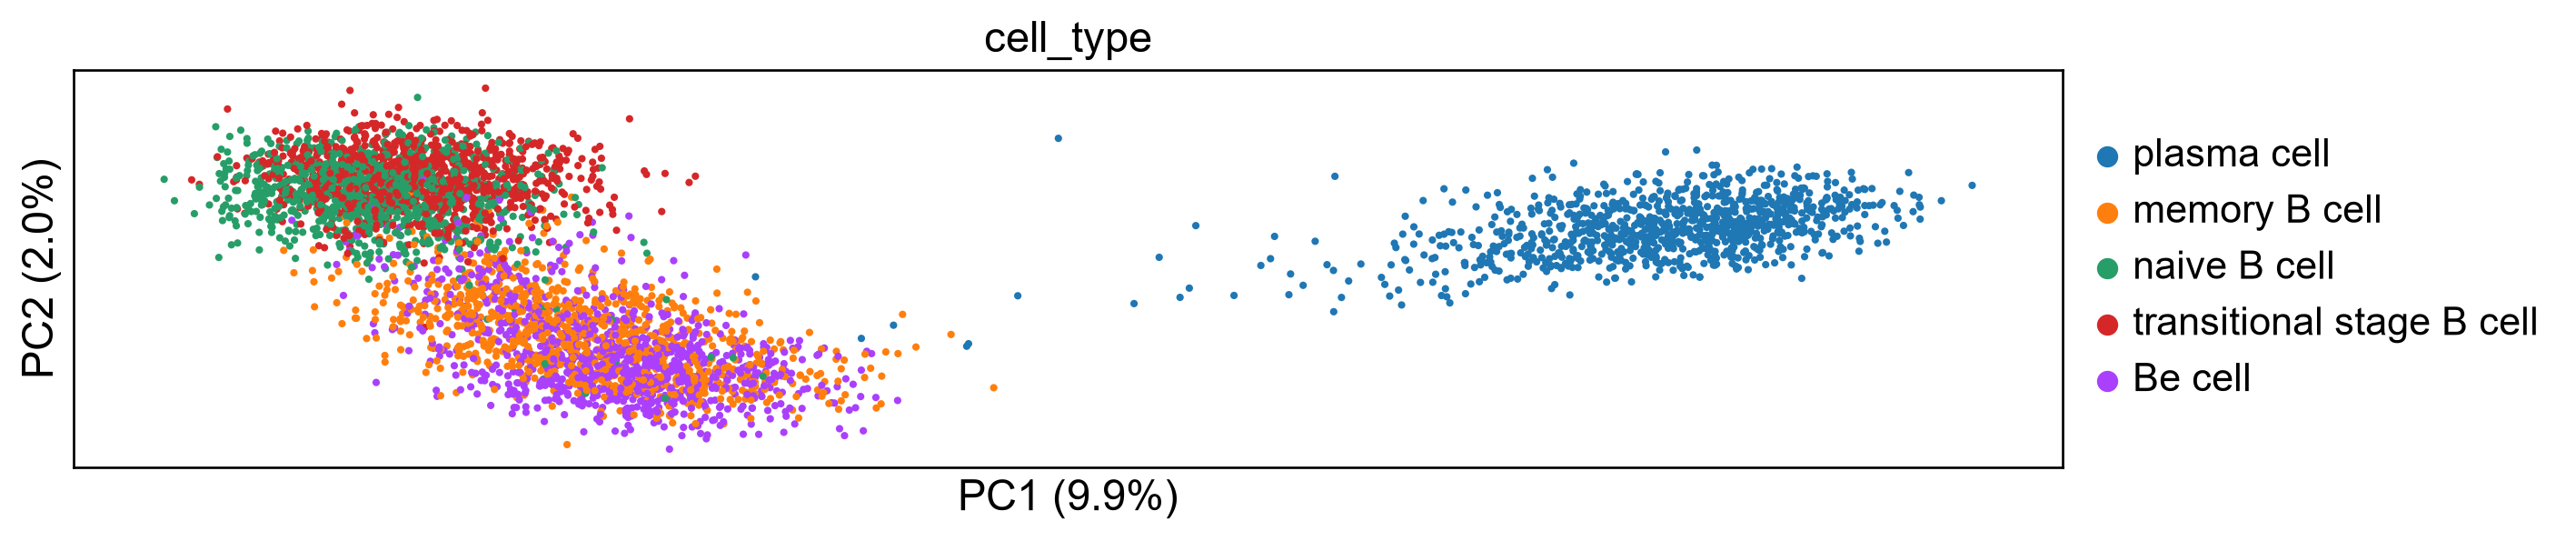

In [9]:
import scanpy as sc
import matplotlib.pyplot as plt

# Increase resolution for crisp text
plt.rcParams['figure.dpi'] = 120 

# 1. Run PCA
sc.tl.pca(analysis_adata)

# 2. Get variance ratios
variance = analysis_adata.uns['pca']['variance_ratio']
pc1_var = variance[0] * 100 # Convert to percentage
pc2_var = variance[1] * 100 # Convert to percentage
ratio = variance[1] / variance[0] # The geometric proportion

# 3. Define size
width = 12
height = width * ratio

# 4. Plot
fig, ax = plt.subplots(figsize=(width, height))

sc.pl.pca(
    analysis_adata, 
    color='cell_type', 
    show=False, 
    ax=ax
)

# 5. Add custom labels with the percentage of explained variance
# .2f means "2 decimal places"
ax.set_xlabel(f"PC1 ({pc1_var:.1f}%)")
ax.set_ylabel(f"PC2 ({pc2_var:.1f}%)")

# 6. Force the aspect ratio to match the variance
ax.set_box_aspect(ratio)

plt.show()

# 4. Student exercise: t-SNE

Apply t-SNE to a suitable representation of the prepared expression data (also using scanpy and matplotlib). Describe what local neighborhoods appear stable and avoid interpreting distances between far-apart groups as quantitative biological differences.

If you are good in time, as an optional exercise, feel free to explore more about the t-SNE. For instance, explore how the perplexity and random seed affect the embedding.   

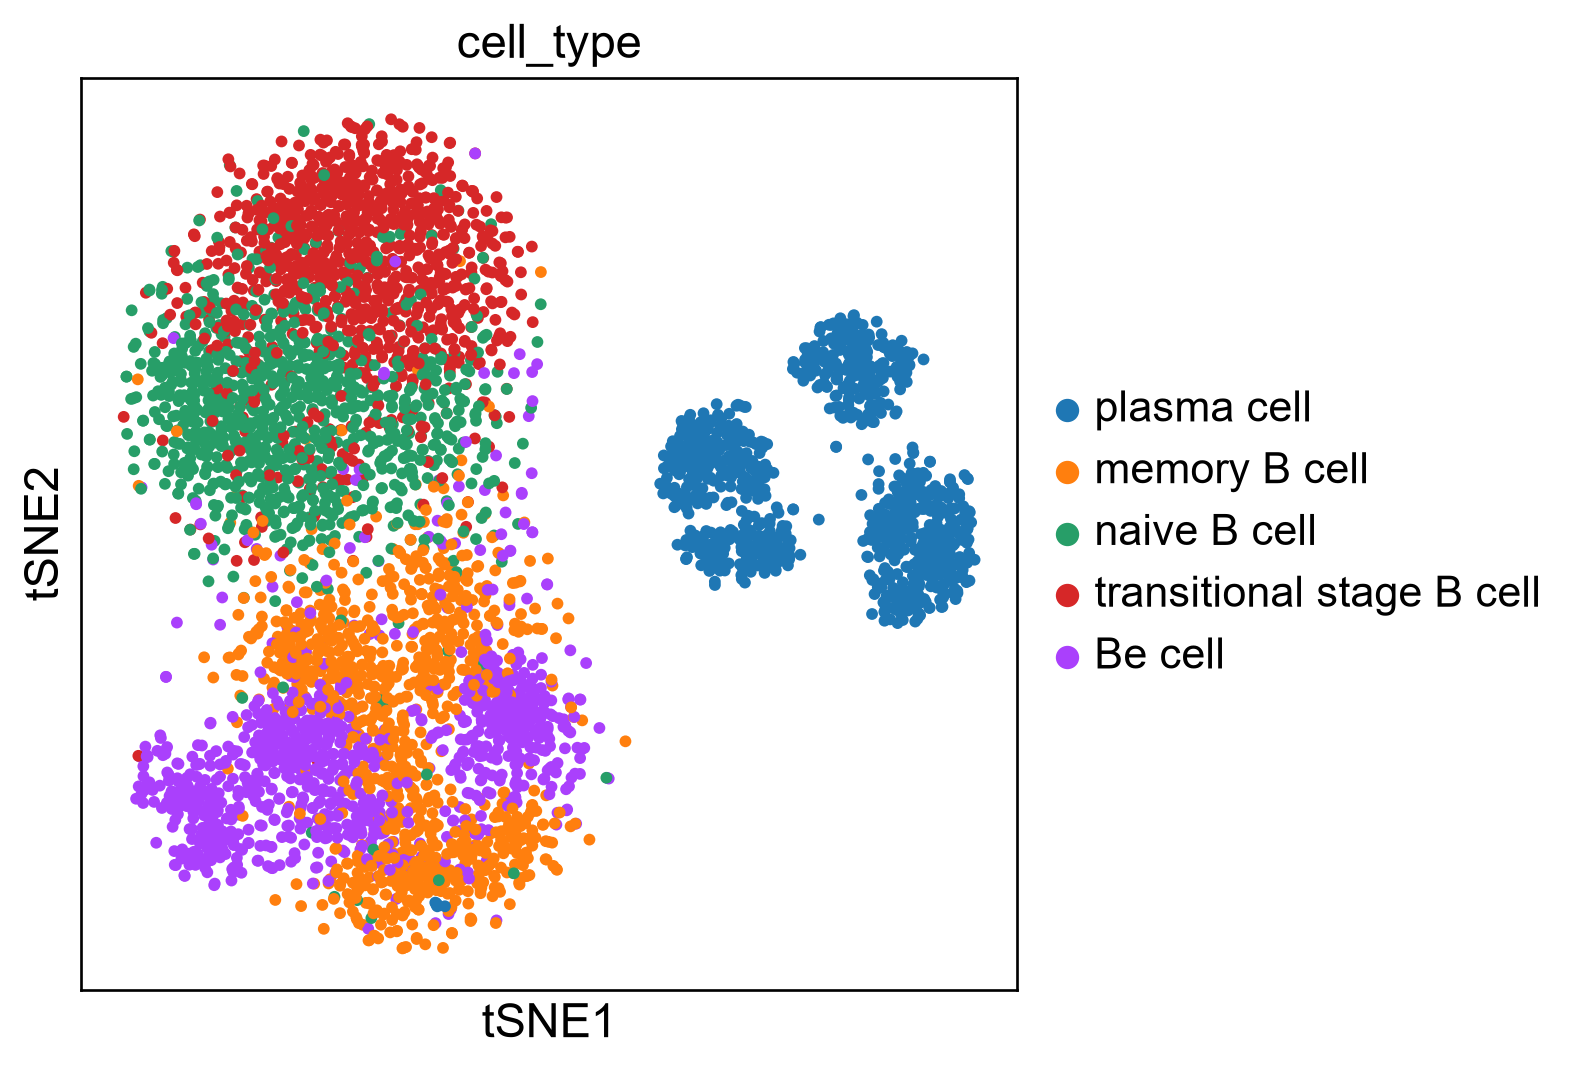

In [12]:
import scanpy as sc
import matplotlib.pyplot as plt

# 1. Run t-SNE
sc.tl.tsne(analysis_adata)

# We set the figure size to (5, 5) for a standard, comfortable view
fig, ax = plt.subplots(figsize=(5, 5))

sc.pl.tsne(
    analysis_adata, 
    color='cell_type', 
    ax=ax, 
    show=False,
    size=50 # Adjust this if the dots look too small/large
)

plt.show()

# 5. Student exercise: UMAP

Apply UMAP to the same cells (also using scanpy and matplotlib).   

Learning resources: 

- [UMAP vs t-SNE for gene expression](https://divingintogeneticsandgenomics.com/learn/compare/umap-vs-tsne/)

If you are good in time, as an optional exercise, feel free to explore more about the UMAP, for instance, play with the `n_neighbors` parameter. Explore the effect of neighborhood size and minimum distance. Compare local group structure with broader arrangement, and distinguish visual separation from evidence of distinct cell identities.

C:\Users\MariaBeatrizWalterCo\miniconda3\envs\env_test\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


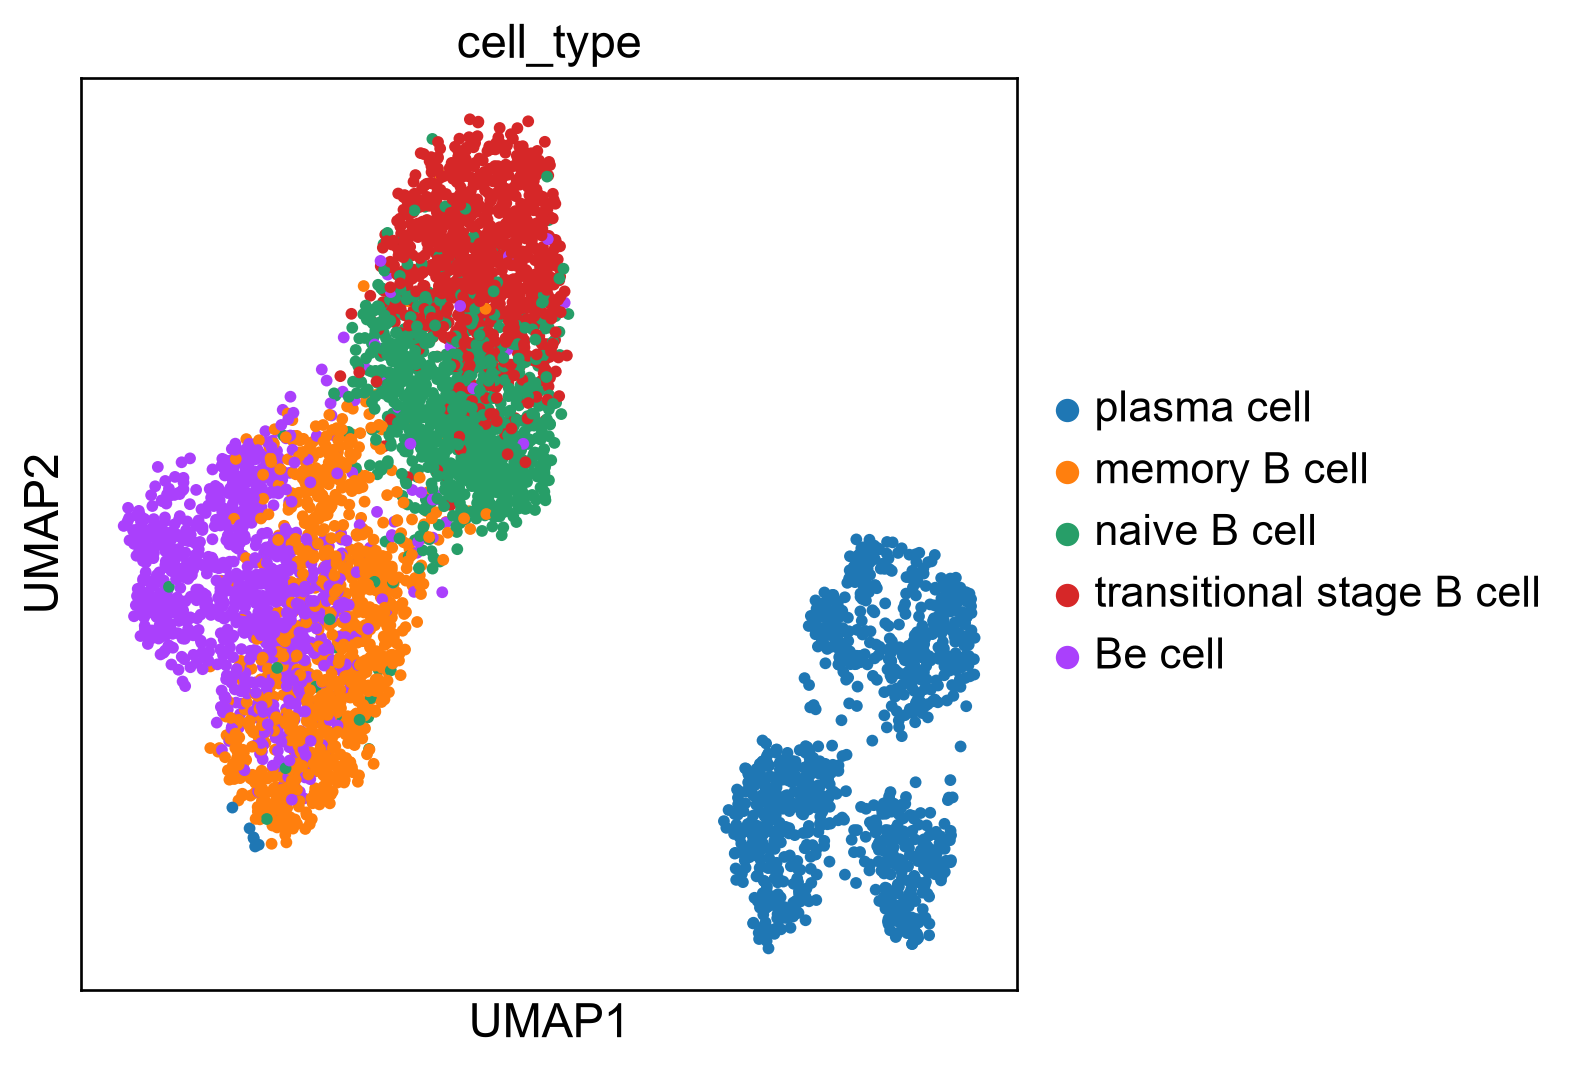

In [13]:
import scanpy as sc
import matplotlib.pyplot as plt

# 1. Ensure the neighborhood graph is calculated
# If you ran t-SNE previously, this is already done, but running it again
# doesn't hurt (it's very fast).
sc.pp.neighbors(analysis_adata, n_neighbors=15, n_pcs=50)

# 2. Compute the UMAP embedding
sc.tl.umap(analysis_adata)

# 3. Plot UMAP
fig, ax = plt.subplots(figsize=(5, 5))

sc.pl.umap(
    analysis_adata, 
    color='cell_type', 
    ax=ax, 
    show=False,
    size=50
)

plt.show()

# 6. Compare and interpret

Compare your three embeddings using the same cells, features, and metadata labels. Briefly discuss:

- What PCA preserves and reveals through its linear axes and explained variance, versus the nonlinear methods.
- How t-SNE and UMAP emphasize neighborhood structure, and what they do not reliably preserve about global distances, cluster size, or density.
- Which structures persist across methods and parameter choices, and which may be algorithm- or preprocessing-dependent.
- Whether apparent patterns align with annotated cell types or instead with other factors; what alternative explanations (sampling and technical variation) remain plausible.